# Pyramid beam-splitter results — visualization

Loads a previously saved results JSON file and produces all plots and tables.
No quantum backends or circuit execution required — only `matplotlib` and `json`.

In [ ]:
# By default, load the most recent pyramid_BS_<date> run from Results/.
# Override RUN_DIR to a Path if you want to inspect a specific run, or point it
# at a legacy root-level JSON (see commented examples below).
from utils.results_io import latest_run

RUN_DIR = latest_run("pyramid_BS")
# RUN_DIR = Path("Results/pyramid_BS_2026-05-21_173030")           # specific dated run
# RUN_DIR = Path("results_pyramid_BS_8_layers_14.5.json")          # legacy root-level JSON
# RUN_DIR = Path("results_pyramid_BS_real_VLQ_layers_15.5.json")   # legacy VLQ-real JSON

limit_for_plotting = 50    # only show bitstrings with more than this many counts


In [ ]:
import json
from pathlib import Path
from math import sqrt

import matplotlib.pyplot as plt
import numpy as np

from utils.results_io import load_run

if RUN_DIR is None:
    raise SystemExit("RUN_DIR is None -- no pyramid_BS_* folder found under Results/ and "
                     "no manual override set in the config cell. Run experiment_N2.1.ipynb "
                     "first, or set RUN_DIR to a legacy JSON path.")

results = load_run(RUN_DIR)

layers = sorted(results.keys())
print(f"Loaded {len(results)} layer(s) from {RUN_DIR}: L = {layers}")
for L in layers:
    r = results[L]
    print(f"  L={L}  nq={r['nq']}  shots={r['shots']}")


## Bitstring histograms per layer

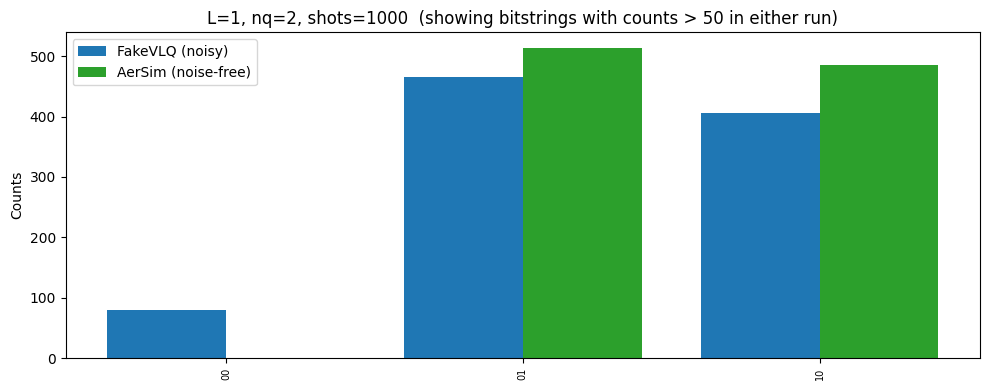

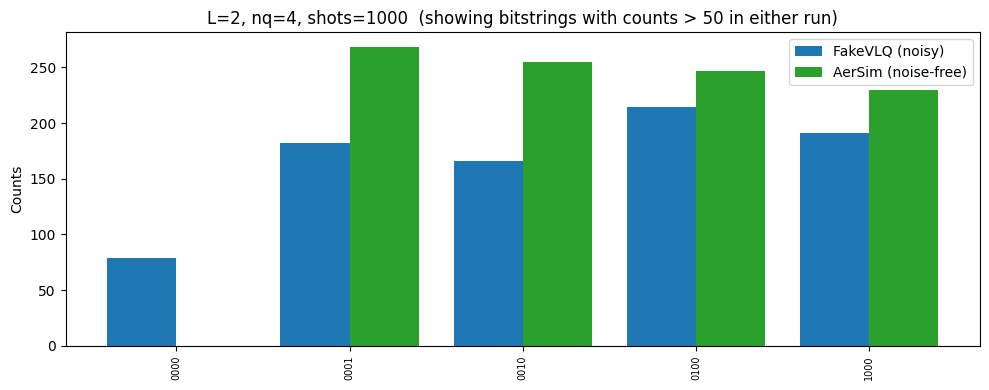

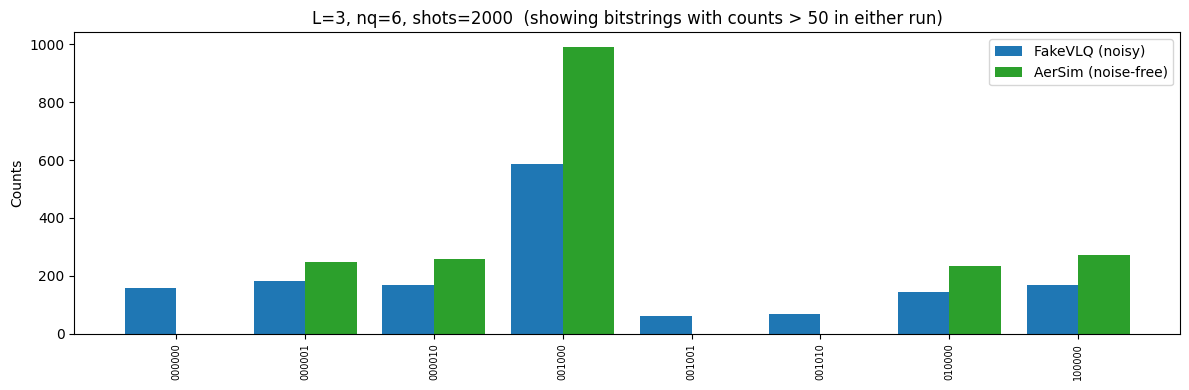

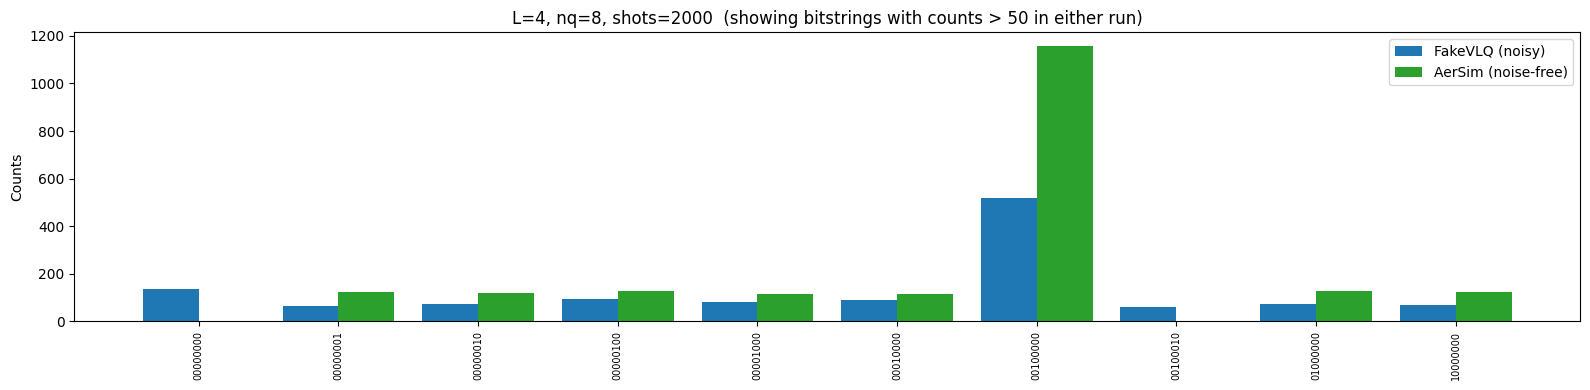

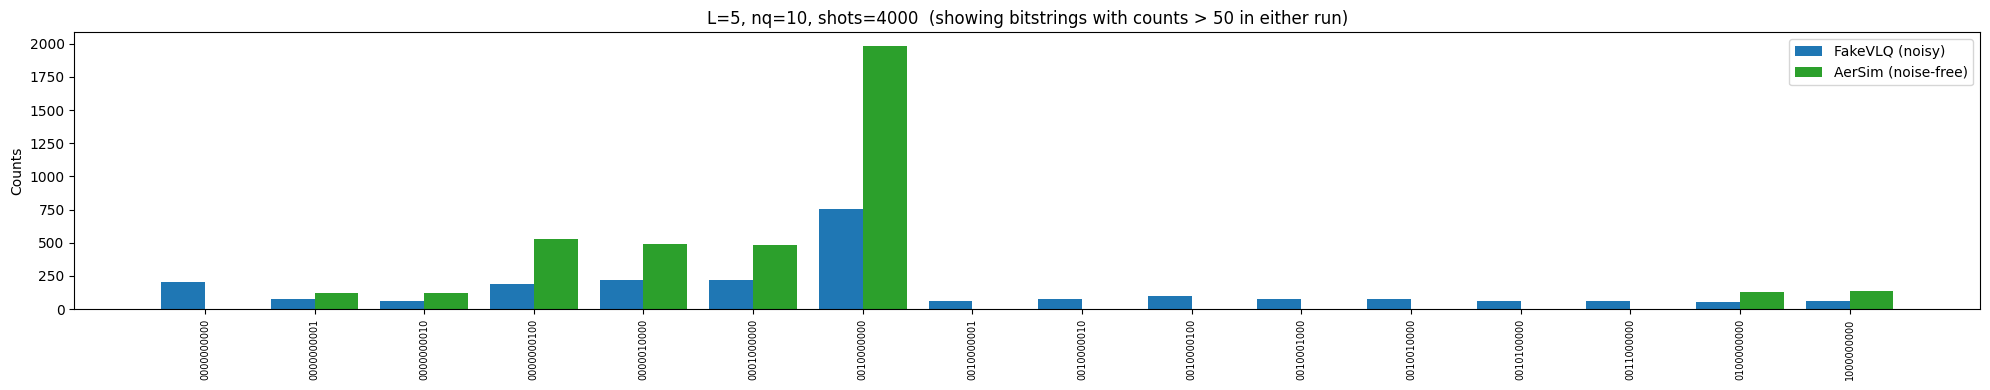

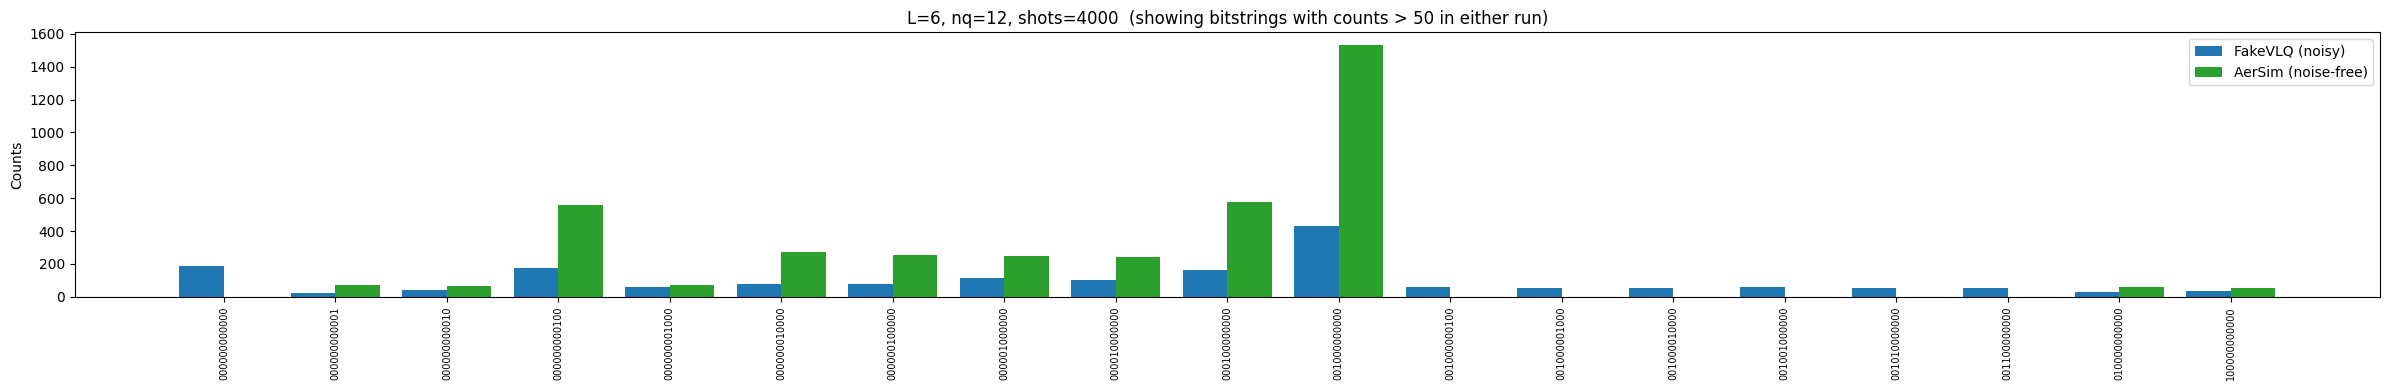

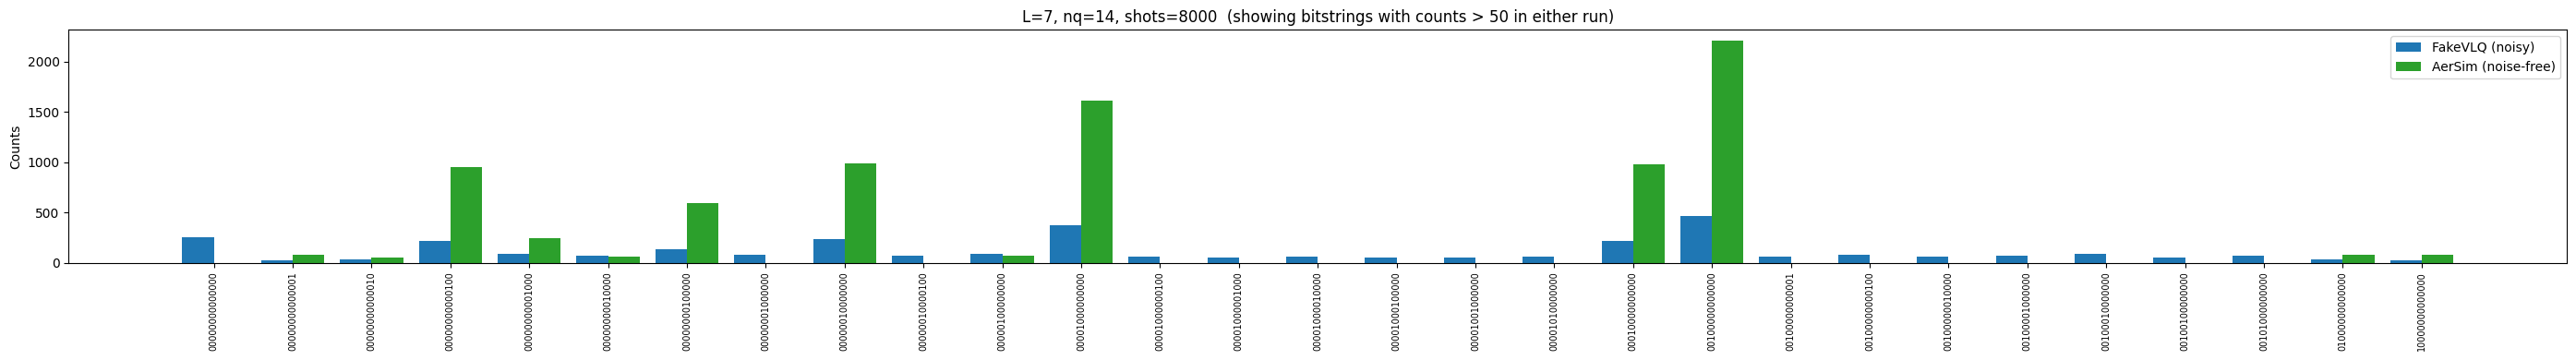

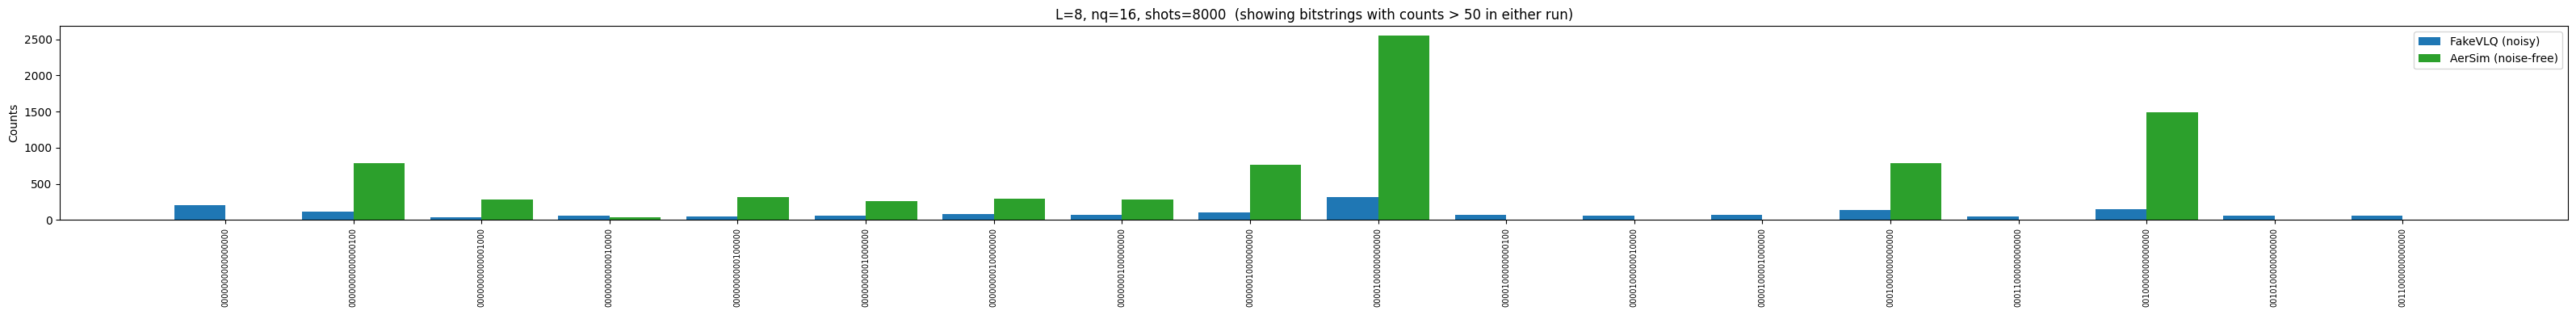

In [41]:
for L in layers:
    r = results[L]
    counts_noisy = r["counts_noisy"]
    counts_noisefree = r["counts_noisefree"]

    # Union of bitstrings appearing above the threshold in either distribution,
    # sorted for a stable x-axis shared by both bars.
    keep = sorted({k for k, v in counts_noisy.items()      if v > limit_for_plotting}
                | {k for k, v in counts_noisefree.items() if v > limit_for_plotting})
    if not keep:
        continue

    noisy_vals     = [counts_noisy.get(k, 0)     for k in keep]
    noisefree_vals = [counts_noisefree.get(k, 0) for k in keep]

    xs = np.arange(len(keep))
    width = 0.4

    fig, ax = plt.subplots(figsize=(max(10, 4 * L), 4))
    ax.bar(xs - width/2, noisy_vals,     width, color='tab:blue',  label='FakeVLQ (noisy)')
    ax.bar(xs + width/2, noisefree_vals, width, color='tab:green', label='AerSim (noise-free)')
    ax.set_xticks(xs)
    ax.set_xticklabels(keep, rotation=90, fontsize=7)
    ax.set_ylabel("Counts")
    ax.set_title(f"L={L}, nq={r['nq']}, shots={r['shots']}  "
                 f"(showing bitstrings with counts > {limit_for_plotting} in either run)")
    ax.legend()
    plt.tight_layout()
    plt.show()


## Hamming-weight distributions

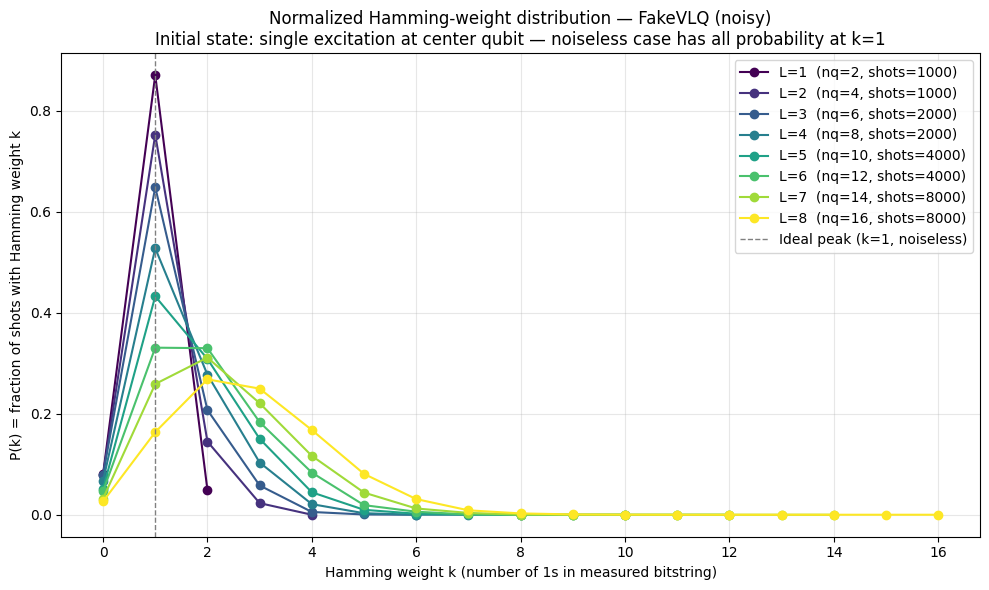

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.get_cmap("viridis")
n_lines = max(1, len(results))

for i, L in enumerate(layers):
    r = results[L]
    p = r["metrics"]["hamming_weight_prob_noisy"]
    ks = list(range(len(p)))
    color = cmap(i / max(1, n_lines - 1))
    ax.plot(ks, p, marker='o', color=color,
            label=f"L={L}  (nq={r['nq']}, shots={r['shots']})")

ax.axvline(x=1, color='grey', linestyle='--', linewidth=1, label='Ideal peak (k=1, noiseless)')
ax.set_xlabel("Hamming weight k (number of 1s in measured bitstring)")
ax.set_ylabel("P(k) = fraction of shots with Hamming weight k")
ax.set_title("Normalized Hamming-weight distribution \u2014 FakeVLQ (noisy)\n"
             "Initial state: single excitation at center qubit \u2014 noiseless case has all probability at k=1")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Circuit depths

In [43]:
print("Circuit depths (gate layers after transpilation)")
print()
print(f"{'L':>3}  {'nq':>4}  {'Original':>10}  {'VLQ':>10}")
print("-" * 35)
for L in layers:
    r = results[L]
    c = r["circuit"]
    print(f"{L:>3}  {r['nq']:>4}  {c['depth_original']:>10}  "
          f"{c['depth_transpiled_VLQ']:>10}")

Circuit depths (gate layers after transpilation)

  L    nq    Original         VLQ
-----------------------------------
  1     2           7          11
  2     4          12          27
  3     6          17          50
  4     8          22          80
  5    10          27         117
  6    12          32         161
  7    14          37         212
  8    16          42         270


## squared Bhattacharyya coefficient (SBC) vs layers

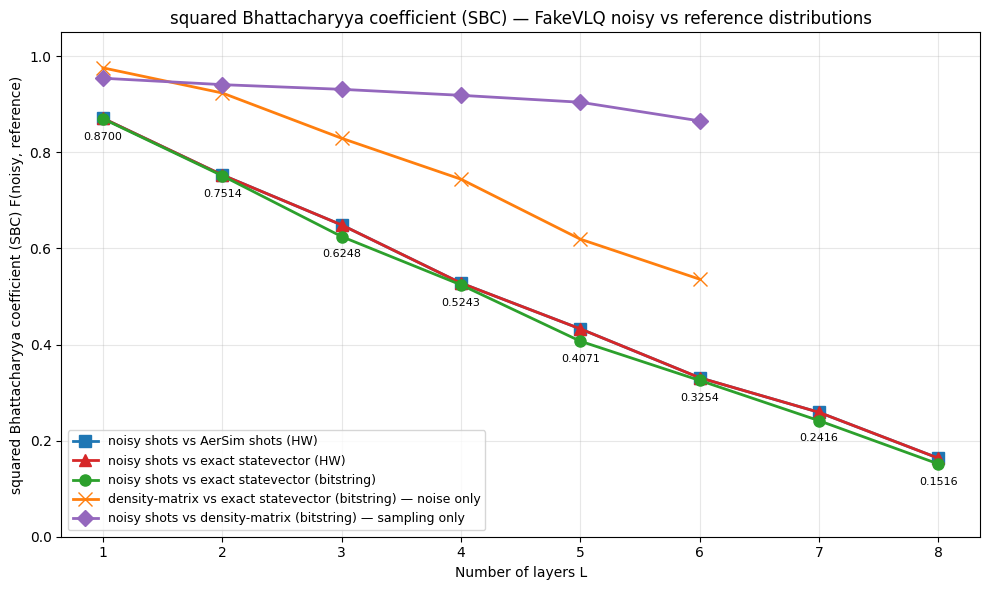

In [44]:
sbc_aersim = [results[L]["metrics"]["SBC_HW_FakeQVL_noiseless"] for L in layers]
sbc_exact_hw = [results[L]["metrics"].get("SBC_HW_FakeVLQ_vs_analytical") for L in layers]
sbc_exact_bs = [results[L]["metrics"].get("SBC_BS_FakeVLQ_vs_analytical") for L in layers]

have_exact_hw = all(x is not None for x in sbc_exact_hw)
have_exact_bs = all(x is not None for x in sbc_exact_bs)

# DM-based metrics may be absent or None for higher layers -- filter per curve.
layers_dm_vs_exact = [L for L in layers
                      if results[L]["metrics"].get("SBC_BS_DM_vs_analytical") is not None]
sbc_bs_dm_vs_exact = [results[L]["metrics"]["SBC_BS_DM_vs_analytical"]
                     for L in layers_dm_vs_exact]
layers_noisy_vs_dm = [L for L in layers
                      if results[L]["metrics"].get("SBC_BS_FakeVLQ_vs_DM") is not None]
sbc_bs_noisy_vs_dm = [results[L]["metrics"]["SBC_BS_FakeVLQ_vs_DM"]
                     for L in layers_noisy_vs_dm]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(layers, sbc_aersim, marker='s', color='tab:blue', linewidth=2, markersize=8,
        label='noisy shots vs AerSim shots (HW)')
if have_exact_hw:
    ax.plot(layers, sbc_exact_hw, marker='^', color='tab:red', linewidth=2, markersize=8,
            label='noisy shots vs exact statevector (HW)')
if have_exact_bs:
    ax.plot(layers, sbc_exact_bs, marker='o', color='tab:green', linewidth=2, markersize=8,
            label='noisy shots vs exact statevector (bitstring)')
    for L, sbc in zip(layers, sbc_exact_bs):
        ax.annotate(f"{sbc:.4f}", (L, sbc), textcoords="offset points",
                    xytext=(0, -15), ha='center', fontsize=8)
else:
    for L, sbc in zip(layers, sbc_aersim):
        ax.annotate(f"{sbc:.4f}", (L, sbc), textcoords="offset points",
                    xytext=(0, 10), ha='center', fontsize=9)
if layers_dm_vs_exact:
    ax.plot(layers_dm_vs_exact, sbc_bs_dm_vs_exact, marker='x', color='tab:orange',
            linewidth=2, markersize=10,
            label='density-matrix vs exact statevector (bitstring) — noise only')
if layers_noisy_vs_dm:
    ax.plot(layers_noisy_vs_dm, sbc_bs_noisy_vs_dm, marker='D', color='tab:purple',
            linewidth=2, markersize=8,
            label='noisy shots vs density-matrix (bitstring) — sampling only')

ax.set_xlabel("Number of layers L")
ax.set_ylabel("squared Bhattacharyya coefficient (SBC) F(noisy, reference)")
ax.set_title("squared Bhattacharyya coefficient (SBC) — FakeVLQ noisy vs reference distributions")
ax.set_xticks(layers)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()

## Summary table

In [28]:
print(f"{'L':>3}  {'nq':>4}  {'shots':>7}  {'depth_VLQ':>10}  "
      f"{'F(AerSim,HW)':>13}  {'F(exact,HW)':>13}  {'F(exact,bits)':>14}  "
      f"{'F(DM,exact)':>13}  {'F(noisy,DM)':>13}")
print("-" * 108)
for L in layers:
    r = results[L]
    m = r["metrics"]
    sbc_a = m["SBC_HW_FakeQVL_noiseless"]
    sbc_eh = m.get("SBC_HW_FakeVLQ_vs_analytical")
    sbc_eb = m.get("SBC_BS_FakeVLQ_vs_analytical")
    sbc_dm_e = m.get("SBC_BS_DM_vs_analytical")
    sbc_n_dm = m.get("SBC_BS_FakeVLQ_vs_DM")
    d = r["circuit"]["depth_transpiled_VLQ"]
    sbc_eh_str  = f"{sbc_eh:13.6f}"  if sbc_eh  is not None else f"{'n/a':>13}"
    sbc_eb_str  = f"{sbc_eb:14.6f}"  if sbc_eb  is not None else f"{'n/a':>14}"
    sbc_dme_str = f"{sbc_dm_e:13.6f}" if sbc_dm_e is not None else f"{'n/a':>13}"
    sbc_ndm_str = f"{sbc_n_dm:13.6f}" if sbc_n_dm is not None else f"{'n/a':>13}"
    print(f"{L:>3}  {r['nq']:>4}  {r['shots']:>7}  {d:>10}  "
          f"{sbc_a:>13.6f}  {sbc_eh_str}  {sbc_eb_str}  {sbc_dme_str}  {sbc_ndm_str}")

  L    nq    shots   depth_VLQ   F(AerSim,HW)    F(exact,HW)   F(exact,bits)    F(DM,exact)    F(noisy,DM)
------------------------------------------------------------------------------------------------------------
  1     2     1000          11       0.871000       0.871000        0.870000       0.976008       0.954454
  2     4     1000          27       0.753000       0.753000        0.751414       0.923689       0.941077
  3     6     2000          50       0.649000       0.649000        0.624803       0.829438       0.931342
  4     8     2000          80       0.528000       0.528000        0.524317       0.744289       0.918883
  5    10     4000         117       0.432750       0.432750        0.407069       0.619474       0.904486
  6    12     4000         161       0.331000       0.331000        0.325399       0.536129       0.865677
  7    14     8000         212       0.259000       0.259000        0.241650            n/a            n/a
  8    16     8000         270     